# Bài kiểm tra thực hành – Phần B

**Họ tên:** Ngô Lâm Tiến  **MSSV:** 524H0195

Hướng dẫn:
- Điền MSSV ở cell đầu tiên rồi chạy lần lượt từ trên xuống.
- Chỉ viết code vào các chỗ có `# TODO`. **Không đổi tên biến, tên hàm.**
- Giữ nguyên output của mọi cell khi nộp (không *Clear output*).
- Lưu notebook thành `MSSV.ipynb`, hình thành `MSSV_b4.png`.

In [1]:
import re
import pandas as pd
import matplotlib.pyplot as plt

MSSV = "524H0195"          # MSSV của bạn
P = int(MSSV[-1])
K = 10 + P % 4
print(f"MSSV = {MSSV} | P = {P} | K = {K} | B4 vẽ: {'bar chart' if P % 2 == 0 else 'box plot'}")

MSSV = 524H0195 | P = 5 | K = 11 | B4 vẽ: box plot


## Sinh dữ liệu
Chạy cell dưới (hoặc chạy `python gen_data.py <MSSV>` trong terminal). File `gen_data.py` phải nằm cùng thư mục với notebook.

In [2]:
import subprocess, sys
subprocess.run([sys.executable, "gen_data.py", MSSV], check=True)
FILE = f"sales_{MSSV}.txt"
with open(FILE, encoding="utf-8") as f:
    lines = f.read().splitlines()
print("Tổng số dòng:", len(lines))
print("\n".join(lines[:8]))

Da tao sales_524H0195.txt (382 dong)
Tổng số dòng: 382
[2025-03-13 15:15] ORDER#0001 | cust=KH120 | branch=td | item=TaiNghe | qty=4 | price=1.165.000 VND
[2025-01-25 12:47] ORDER#0002 | cust=KH705 | branch=Q7 | item=BanPhim | qty=1 | price=830.000 VND
ERROR: timeout while reading POS
[2025-02-23 20:24] ORDER#0003 | cust=KH265 | branch=Q7 | item=ManHinh | qty=3 | price=4.20tr
[2025-02-23 20:24] ORDER#0003 | cust=KH265 | branch=Q7 | item=ManHinh | qty=3 | price=4.20tr
[2025-02-12 19:25] ORDER#0004 | cust=KH544 | branch=TD | item=Chuot | qty=1 | price=0.24tr
[2025-03-08 19:13] ORDER#0005 | cust=KH838 | branch= Q1  | item=ManHinh | qty=3 | price=4.068.000 VND
[2025-03-17 15:36] ORDER#0006 | cust=KH838 | branch=Q1 | item=Chuot | qty=1 | price=238.000 VND


## B1 – Đọc và tách trường bằng regex
Tách mỗi dòng ORDER thành 7 trường `date, order_id, cust, branch, item, qty, price` (giữ dạng chuỗi), thu tập `order_id` bị huỷ, đếm dòng rác.

In [3]:
ORDER_PATTERN = (r"\[(\d{4}-\d{2}-\d{2} \d{2}:\d{2})\]\s*ORDER#(\d+)\s*\|\s*"
                 r"cust=(\w+)\s*\|\s*branch=([^|]+?)\s*\|\s*item=([^|]+?)\s*\|\s*"
                 r"qty=(\S+)\s*\|\s*price=(.+?)\s*$")
CANCEL_PATTERN = r"CANCEL\s+ORDER#(\d+)"

rows = []          # mỗi phần tử là tuple 7 trường
cancelled = set()  # tập order_id bị huỷ
junk = 0           # số dòng rác

for line in lines:
    m = re.search(ORDER_PATTERN, line)
    if m:                       # dòng ORDER: lấy đủ 7 nhóm
        rows.append(m.groups())
        continue
    m = re.search(CANCEL_PATTERN, line)
    if m:                       # dòng CANCEL: chỉ quan tâm order_id
        cancelled.add(m.group(1))
        continue
    junk += 1                   # còn lại (WARN/INFO/#/----) là rác

raw = pd.DataFrame(rows, columns=["date", "order_id", "cust", "branch", "item", "qty", "price"])
print("B1 | ORDER:", len(raw), "| đơn huỷ:", len(cancelled), "| dòng rác:", junk)
raw.head()

B1 | ORDER: 346 | đơn huỷ: 12 | dòng rác: 24


,date,order_id,cust,branch,item,qty,price
0,2025-03-13 15:15,0001,KH120,td,TaiNghe,4,1.165.000 VND
1,2025-01-25 12:47,0002,KH705,Q7,BanPhim,1,830.000 VND
2,2025-02-23 20:24,0003,KH265,Q7,ManHinh,3,4.20tr
3,2025-02-23 20:24,0003,KH265,Q7,ManHinh,3,4.20tr
4,2025-02-12 19:25,0004,KH544,TD,Chuot,1,0.24tr


## B2 – Làm sạch đúng thứ tự
1. Bỏ trùng theo `order_id` (giữ lần đầu) → 2. Bỏ đơn bị huỷ → 3. Bỏ `qty` là `?`, đổi sang `int`, bỏ `qty > 50` → 4. Chuẩn hoá `branch`, đổi `price` bằng `to_vnd` → 5. Điền giá thiếu bằng trung vị cùng mặt hàng (`groupby(...).transform(...)`).

In [4]:
df = raw.copy()

# Bước 1: bỏ dòng trùng theo order_id, giữ lần xuất hiện đầu tiên
df = df.drop_duplicates(subset="order_id", keep="first")
n_step1 = len(df)

# Bước 2: bỏ đơn bị huỷ (order_id nằm trong tập cancelled)
df = df[~df["order_id"].isin(cancelled)]
n_step2 = len(df)

# Bước 3: bỏ qty '?' -> đổi sang int -> bỏ qty > 50 (số nhập nhầm)
df = df[df["qty"] != "?"].copy()
df["qty"] = df["qty"].astype(int)
df = df[df["qty"] <= 50]
n_step3 = len(df)

df = df.reset_index(drop=True)

print("B2 | sau bước 1:", n_step1, "| sau bước 2:", n_step2, "| sau bước 3:", n_step3)

B2 | sau bước 1: 322 | sau bước 2: 310 | sau bước 3: 296


In [5]:
def to_vnd(s):
    """Đổi chuỗi giá ('15.861.000 VND', '15861000', '15.86tr', '?') sang số VND; '?' trả về NaN."""
    t = str(s).strip().lower().replace("vnd", "").strip()
    if t in ("?", "", "nan"):
        return float("nan")
    if t.endswith("tr"):                                   # 'tr' = triệu, phần số có thể dùng . hoặc ,
        return float(t[:-2].strip().replace(",", ".")) * 1_000_000
    return float(t.replace(".", "").replace(",", "."))     # '1.234.000' -> 1234000, '1,5' -> 1.5

# Bước 4: chuẩn hoá branch (bỏ khoảng trắng thừa + viết hoa), đổi price sang số VND
df["branch"] = df["branch"].str.strip().str.upper()
df["price"] = df["price"].map(to_vnd)

# Bước 5: đếm giá thiếu TRƯỚC khi điền, rồi điền bằng trung vị giá của cùng mặt hàng
n_missing_price = int(df["price"].isna().sum())
df["price"] = df["price"].fillna(df.groupby("item")["price"].transform("median"))

print("B2 | số giá bị thiếu:", n_missing_price)
df.head()

B2 | số giá bị thiếu: 21


,date,order_id,cust,branch,item,qty,price
0,2025-03-13 15:15,0001,KH120,TD,TaiNghe,4,1165000.0
1,2025-01-25 12:47,0002,KH705,Q7,BanPhim,1,830000.0
2,2025-02-23 20:24,0003,KH265,Q7,ManHinh,3,4200000.0
3,2025-02-12 19:25,0004,KH544,TD,Chuot,1,240000.0
4,2025-03-08 19:13,0005,KH838,Q1,ManHinh,3,4068000.0


## B3 – Phân tích

In [6]:
df["revenue"] = df["qty"] * df["price"]

# a) Tổng doanh thu và doanh thu theo chi nhánh
total_revenue = df["revenue"].sum()
branch_revenue = df.groupby("branch")["revenue"].sum().sort_values(ascending=False)
print("B3a | tổng doanh thu:", f"{total_revenue:,.0f}", "VND")
print(branch_revenue)

B3a | tổng doanh thu: 2,792,018,000 VND
branch
TD    1.016714e+09
Q7    7.353845e+08
Q1    6.204125e+08
BT    4.195065e+08
Name: revenue, dtype: float64


In [7]:
# share = doanh thu đơn / tổng doanh thu của chi nhánh chứa đơn đó
df["share"] = df["revenue"] / df.groupby("branch")["revenue"].transform("sum")

top_share = df.loc[df["share"].idxmax(), ["order_id", "branch", "share"]]
print("B3b | đơn có share lớn nhất:", top_share["order_id"],
      "| chi nhánh:", top_share["branch"],
      "| share:", f"{top_share['share']:.2%}")

B3b | đơn có share lớn nhất: 0258 | chi nhánh: BT | share: 20.24%


In [8]:
loyal = df.groupby("cust").filter(lambda g: len(g) >= K)
print("B3c | số khách:", loyal["cust"].nunique(), "| số đơn:", len(loyal))
print("Mốc K =", K, "đơn/khách")

B3c | số khách: 16 | số đơn: 216
Mốc K = 11 đơn/khách


## B4 – Trực quan hoá chỉ bằng matplotlib
Chỉ dùng matplotlib và list/dict thuần (được dùng `.tolist()` để lấy dữ liệu). **Không** dùng `df.plot`, không dùng seaborn.
- P chẵn: bar chart doanh thu theo chi nhánh, tô màu khác cho chi nhánh cao nhất, ghi giá trị trên mỗi cột.
- P lẻ: box plot giá trị đơn hàng (`revenue`) theo 5 mặt hàng, trục y log, đánh dấu mặt hàng có trung vị cao nhất.

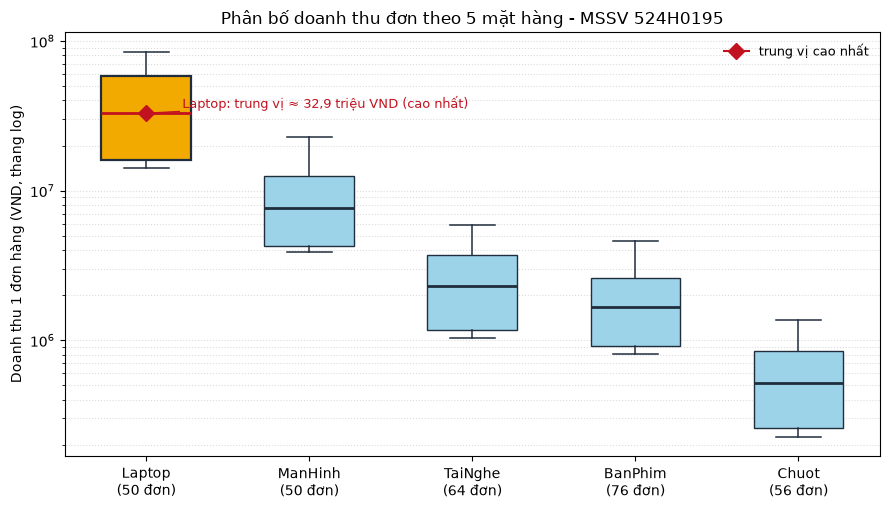

In [9]:
import statistics

fig, ax = plt.subplots(figsize=(9, 5.2))

if P % 2 == 0:
    # ---------- P chẵn: bar chart doanh thu theo chi nhánh ----------
    labels = branch_revenue.index.tolist()
    values = branch_revenue.tolist()
    colors = ["#f2a900" if i == 0 else "#9dd3e8" for i in range(len(values))]

    bars = ax.bar(labels, values, color=colors, edgecolor="#1f2d3d", linewidth=1.2)
    for b, v in zip(bars, values):
        ax.annotate(f"{v / 1e9:.3f} tỷ",
                    xy=(b.get_x() + b.get_width() / 2, v),
                    xytext=(0, 4), textcoords="offset points",
                    ha="center", fontsize=9)
    ax.set_ylabel("Doanh thu (VND)")
    ax.set_title(f"Doanh thu theo chi nhánh - MSSV {MSSV} (cao nhất: {labels[0]})")
    ax.grid(axis="y", linestyle=":", alpha=0.45)
    ax.set_axisbelow(True)
else:
    # ---------- P lẻ: box plot doanh thu đơn theo 5 mặt hàng, trục y log ----------
    top5 = df.groupby("item")["revenue"].sum().sort_values(ascending=False).head(5).index.tolist()
    data = [df.loc[df["item"] == it, "revenue"].tolist() for it in top5]
    counts = [len(d) for d in data]
    medians = [statistics.median(d) for d in data]
    best = max(range(len(top5)), key=lambda i: medians[i])

    bp = ax.boxplot(data, patch_artist=True, widths=0.55)
    for i in range(len(top5)):
        picked = i == best
        bp["boxes"][i].set(facecolor="#f2a900" if picked else "#9dd3e8",
                           edgecolor="#1f2d3d", linewidth=1.6 if picked else 1.0)
        for part in ("whiskers", "caps"):
            for artist in bp[part][2 * i: 2 * i + 2]:
                artist.set(color="#1f2d3d", linewidth=1.1)
        bp["medians"][i].set(color="#c1121f" if picked else "#1f2d3d", linewidth=2.0)
        bp["fliers"][i].set(marker="o", markersize=3.2,
                            markerfacecolor="#8d99ae", markeredgecolor="#8d99ae")

    ax.set_yscale("log")
    ax.set_xticks(range(1, len(top5) + 1))
    ax.set_xticklabels([f"{it}\n({c} đơn)" for it, c in zip(top5, counts)])
    ax.set_ylabel("Doanh thu 1 đơn hàng (VND, thang log)")
    ax.set_title(f"Phân bố doanh thu đơn theo 5 mặt hàng - MSSV {MSSV}")
    ax.grid(axis="y", which="both", linestyle=":", alpha=0.45)
    ax.set_axisbelow(True)

    ax.plot([best + 1], [medians[best]], marker="D", markersize=8,
            color="#c1121f", zorder=5, label="trung vị cao nhất")
    med_txt = f"{medians[best] / 1e6:.1f}".replace(".", ",")   # 29,5 kiểu Việt Nam
    ax.annotate(f"{top5[best]}: trung vị ≈ {med_txt} triệu VND (cao nhất)",
                xy=(best + 1, medians[best]),
                xytext=(-26 if best == len(top5) - 1 else 26, 7), textcoords="offset points",
                ha="right" if best == len(top5) - 1 else "left", va="center",
                fontsize=9.5, color="#c1121f",
                arrowprops=dict(arrowstyle="-", color="#c1121f", lw=0.9,
                                shrinkA=0, shrinkB=6))
    ax.legend(loc="upper right", frameon=False, fontsize=9)

plt.tight_layout()
plt.savefig(f"{MSSV}_b4.png", dpi=150)
plt.show()

**Nhận xét B4 (1 câu, có một con số):** Trong 5 mặt hàng, Laptop có trung vị doanh thu mỗi đơn cao nhất (~32,9 triệu VND/đơn), gấp khoảng 64 lần Chuot (~0,52 triệu VND/đơn), nên trục y phải để thang log mới thấy được cả 5 mặt hàng.